# AWS ML Tasks - Week 02: End-to-End Semantic Search & Vector Retrieval Pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EyobTesfaye8/AWS_tasks/blob/main/week-02/AWS_ML_Semantic_Search.ipynb)
![Python](https://img.shields.io/badge/Python-3.10%2B-blue.svg)
![ChromaDB](https://img.shields.io/badge/VectorDB-ChromaDB-green.svg)
![SentenceTransformers](https://img.shields.io/badge/Embeddings-MiniLM--L6--v2-orange.svg)

---

### Project Overview
This notebook implements an end-to-end semantic retrieval system tailored for the **AWS Cloud & Machine Learning FAQ Assistant**. It covers the complete pipeline:
1. **Data Ingestion & Cleaning**: Inspecting raw data, handling missing values, removing duplicate records, trimming whitespace, and standardizing categories.
2. **REST API & JSON Handling**: Consuming REST endpoints, verifying HTTP status codes, and parsing JSON responses with offline fallbacks.
3. **Text Tokenization & Document Chunking**: Preprocessing text and segmenting documents into overlapping passages.
4. **Vector Embeddings**: Generating 384-dimensional dense semantic vectors using `sentence-transformers/all-MiniLM-L6-v2`.
5. **Pure NumPy Semantic Retrieval**: Implementing cosine similarity vector math and nearest-neighbor ranking without external search libraries.
6. **Vector Database Integration (ChromaDB)**: Indexing embeddings, original texts, and structured metadata into a persistent ChromaDB collection.
7. **Structured Metadata Filtering**: Restricting semantic search by category (e.g., `aws_cloud`, `machine_learning`, `academics`, `support`).
8. **Comparative Benchmarks & Error Analysis**: Evaluating retrieval across diverse user queries, comparing NumPy vs. ChromaDB, and diagnosing a low-performing ambiguous query.


## 1. Setup & Library Imports

We import standard utilities along with numerical, machine learning, and vector database libraries:
- `numpy`: Vectorized math and array operations
- `pandas`: Tabular data cleaning and manipulation
- `matplotlib`: Data visualization
- `requests`: HTTP API requests
- `sentence_transformers`: Sentence and document embedding generation
- `chromadb`: Persistent vector database storage and Approximate Nearest Neighbor (ANN) search


In [1]:
import os
import re
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Vector libraries
from sentence_transformers import SentenceTransformer
import chromadb
from sklearn.metrics.pairwise import cosine_similarity

%matplotlib inline
print("All core libraries imported successfully!")


/home/eyob/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All core libraries imported successfully!


## 2. Data Ingestion & Data Quality Cleaning

We load `data/raw_messy_faqs.csv`, which intentionally contains real-world data quality issues:
- Missing/null values
- Duplicate records
- Irregular whitespace and inconsistent casing in categories

We implement systematic cleaning functions to detect, report, and resolve each defect.


In [2]:
# 1. Load the raw, intentionally messy dataset
data_candidates = ["data/raw_messy_faqs.csv", "week-02/data/raw_messy_faqs.csv"]
data_path = next((p for p in data_candidates if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError("Could not find raw_messy_faqs.csv. Please verify the path.")

df_raw = pd.read_csv(data_path)
print(f"[INFO] Loaded raw dataset from '{data_path}'")
print(f"Dataset Shape: {df_raw.shape}")
print("\nMissing Values Per Column:")
print(df_raw.isna().sum())
print(f"\nDuplicate Rows Detected: {df_raw.duplicated().sum()}")

display(df_raw.tail(5))


[INFO] Loaded raw dataset from 'data/raw_messy_faqs.csv'
Dataset Shape: (23, 4)

Missing Values Per Column:
id          0
question    0
answer      1
category    0
dtype: int64

Duplicate Rows Detected: 0


,id,question,answer,category
18,faq_019,What should I do if my GitHub repository push ...,GitHub requires Personal Access Tokens (PAT) o...,support
19,faq_020,How do I schedule 1-on-1 mentorship sessions w...,Mentorship slots are published every Monday mo...,support
20,faq_021,How do I reset my account password?,Use the forgot password page link sent to your...,SUPPORT
21,faq_021,How do I reset my account password?,Use the forgot password page link sent to your...,SUPPORT
22,faq_022,Can I submit late work?,NaN,academics


In [3]:
def clean_faq_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """
    Cleans raw FAQ data:
    1. Detects and drops rows with missing essential fields.
    2. Strips whitespace and normalizes text and category casing.
    3. Identifies and removes duplicate entries.
    4. Computes min-max normalized question lengths.
    """
    cleaned = df.copy()

    # 1. Handle missing values
    initial_len = len(cleaned)
    cleaned = cleaned.dropna(subset=['question', 'answer'])
    print(f"Dropped {initial_len - len(cleaned)} rows with missing critical fields.")

    # 2. Text normalization
    for col in ['id', 'question', 'answer', 'category']:
        if col in cleaned.columns:
            cleaned[col] = cleaned[col].astype(str).str.strip()

    if 'category' in cleaned.columns:
        cleaned['category'] = cleaned['category'].str.lower()
        print("Standardized 'category' column to lowercase stripped text.")

    # 3. Duplicate handling
    before_dedup = len(cleaned)
    cleaned = cleaned.drop_duplicates(subset=['question', 'answer']).reset_index(drop=True)
    print(f"Removed {before_dedup - len(cleaned)} duplicate rows.")

    # 4. Feature Engineering: Min-Max Length Normalization
    lengths = cleaned['question'].str.len().to_numpy()
    min_len, max_len = lengths.min(), lengths.max()
    cleaned['norm_length'] = (lengths - min_len) / (max_len - min_len) if max_len != min_len else 1.0
    print(f"Computed normalized question lengths in range [0, 1].")

    return cleaned

df_cleaned = clean_faq_dataset(df_raw)
print(f"\nCleaned Dataset Shape: {df_cleaned.shape}")
display(df_cleaned.head(5))


Dropped 1 rows with missing critical fields.
Standardized 'category' column to lowercase stripped text.
Removed 1 duplicate rows.
Computed normalized question lengths in range [0, 1].

Cleaned Dataset Shape: (21, 5)


,id,question,answer,category,norm_length
0,faq_001,How do I create and configure an S3 bucket on ...,"To create an S3 bucket, log in to the AWS Mana...",aws_cloud,0.865385
1,faq_002,What is Amazon SageMaker and how is it used fo...,Amazon SageMaker is a fully managed service th...,aws_cloud,0.884615
2,faq_003,How can I avoid unexpected AWS charges and mon...,Set up AWS Budgets and CloudWatch Billing Alar...,aws_cloud,0.653846
3,faq_004,What are AWS IAM roles and why should I avoid ...,AWS Identity and Access Management (IAM) roles...,aws_cloud,0.750000
4,faq_005,What is Amazon Bedrock and which foundation mo...,Amazon Bedrock is a fully managed service that...,aws_cloud,0.576923


### Visualizing FAQ Category Distribution

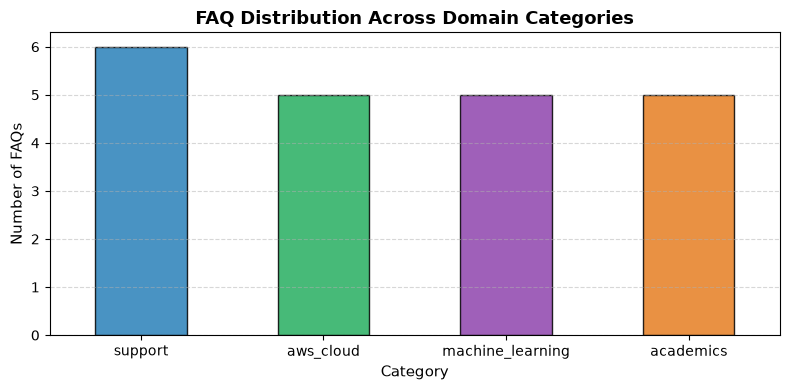

In [4]:
category_counts = df_cleaned['category'].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))
category_counts.plot(kind='bar', color=['#2980b9', '#27ae60', '#8e44ad', '#e67e22'], ax=ax, edgecolor='black', alpha=0.85)

ax.set_title("FAQ Distribution Across Domain Categories", fontsize=13, fontweight='bold')
ax.set_xlabel("Category", fontsize=11)
ax.set_ylabel("Number of FAQs", fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Web API Request & JSON Handling

Demonstrating robust external API communication: making HTTP GET requests, validating response status codes, handling JSON payloads, and implementing offline error resilience.


In [5]:
def fetch_api_sample(url="https://jsonplaceholder.typicode.com/todos/1"):
    print(f"Sending GET request to API: {url}")
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        data = response.json()
        print(f"HTTP Status: {response.status_code}")
        print("Received JSON Payload:")
        print(json.dumps(data, indent=2))
        return data
    except requests.RequestException as e:
        print(f"[NOTE] Remote network unavailable ({e}). Using offline mock response.")
        fallback = {"userId": 1, "id": 1, "title": "AWS ML Offline Task Demo", "completed": True}
        print(json.dumps(fallback, indent=2))
        return fallback

api_payload = fetch_api_sample()


Sending GET request to API: https://jsonplaceholder.typicode.com/todos/1
HTTP Status: 200
Received JSON Payload:
{
  "userId": 1,
  "id": 1,
  "title": "delectus aut autem",
  "completed": false
}


## 4. Document Chunking & Text Preparation

In Retrieval-Augmented Generation (RAG) and search pipelines, documents often exceed embedding model context windows. **Chunking** splits long passages into smaller, coherent chunks while **overlap** preserves context across split boundaries.


In [6]:
def chunk_document(text: str, chunk_size: int = 120, overlap: int = 30) -> list:
    """
    Partitions text into chunks with specified character size and overlap.
    """
    chunks = []
    start = 0
    text_len = len(text)
    
    while start < text_len:
        end = min(start + chunk_size, text_len)
        chunk = text[start:end].strip()
        if chunk:
            chunks.append(chunk)
        if end == text_len:
            break
        start += (chunk_size - overlap)
        
    return chunks

sample_policy = (
    "Amazon SageMaker is a fully managed cloud service that provides developers and data scientists "
    "with the tools to build, train, tune, and deploy machine learning models at scale. SageMaker provides "
    "managed compute instances running optimized pre-built containers for PyTorch, TensorFlow, and HuggingFace, "
    "as well as serverless inference endpoints for scalable deployment."
)

chunks = chunk_document(sample_policy, chunk_size=120, overlap=30)
print(f"Original Text Length: {len(sample_policy)} characters\nGenerated {len(chunks)} chunks:\n")
for i, c in enumerate(chunks):
    print(f"Chunk {i + 1} ({len(c)} chars): '{c}'")


Original Text Length: 370 characters
Generated 4 chunks:

Chunk 1 (119 chars): 'Amazon SageMaker is a fully managed cloud service that provides developers and data scientists with the tools to build,'
Chunk 2 (120 chars): 'ists with the tools to build, train, tune, and deploy machine learning models at scale. SageMaker provides managed compu'
Chunk 3 (120 chars): 'geMaker provides managed compute instances running optimized pre-built containers for PyTorch, TensorFlow, and HuggingFa'
Chunk 4 (100 chars): 'rch, TensorFlow, and HuggingFace, as well as serverless inference endpoints for scalable deployment.'


## 5. Dense Vector Embeddings

We use the lightweight, high-performance `sentence-transformers/all-MiniLM-L6-v2` model to map text passages into 384-dimensional dense semantic vectors.

We construct composite search strings formatted as:
```text
Question: <FAQ Question>
Answer: <FAQ Answer>
```
Embedding both question and answer ensures that queries match either the user's inquiry phrasing or the technical details contained in the resolution.


In [7]:
# Load Sentence Transformer model
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Create composite search text
df_cleaned["search_text"] = (
    "Question: " + df_cleaned["question"] + "\nAnswer: " + df_cleaned["answer"]
)

# Encode all FAQ documents with L2 normalization
faq_embeddings = model.encode(
    df_cleaned["search_text"].tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

print(f"Total documents embedded: {len(df_cleaned)}")
print(f"Embedding matrix shape: {faq_embeddings.shape}")
print(f"Embedding dimension: {faq_embeddings.shape[1]}")
print(f"Vector preview (first 8 values of doc 0):\n{faq_embeddings[0][:8]}")


Batches: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.81it/s]

Total documents embedded: 21
Embedding matrix shape: (21, 384)
Embedding dimension: 384
Vector preview (first 8 values of doc 0):
[-0.00242985 -0.01645891 -0.13252097 -0.04291792  0.01303226  0.06237419
 -0.02196458 -0.02595219]


## 6. Semantic Search with Pure NumPy

Because our embeddings are $L_2$-normalized ($\| \mathbf{v} \|_2 = 1$), the **cosine similarity** between a query vector $\mathbf{q}$ and document vectors $\mathbf{D}$ simplifies directly to their matrix dot product:

$$	ext{Cosine Similarity}(\mathbf{q}, \mathbf{d}) = \mathbf{q} \cdot \mathbf{d} = \sum_{i=1}^{d} q_i d_i$$

Below, we implement semantic search and top-k retrieval using purely vectorized NumPy calculations.


In [8]:
def numpy_semantic_search(query: str, df: pd.DataFrame, vectors: np.ndarray, top_k: int = 3, category: str = None) -> pd.DataFrame:
    """
    Retrieves the top-k most semantically relevant documents using pure NumPy vector operations.
    Supports optional category metadata filtering.
    """
    # Optional category filter
    if category is not None:
        mask = (df["category"] == category.strip().lower()).to_numpy()
        candidates = df[mask].reset_index(drop=True)
        candidate_vectors = vectors[mask]
        if len(candidates) == 0:
            return pd.DataFrame(columns=["id", "question", "answer", "category", "similarity"])
    else:
        candidates = df
        candidate_vectors = vectors

    # 1. Embed query vector
    query_vector = model.encode([query], normalize_embeddings=True)[0]

    # 2. Compute cosine similarity via dot product
    scores = np.dot(candidate_vectors, query_vector)

    # 3. Rank top indices
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = candidates.iloc[top_indices][["id", "question", "answer", "category"]].copy()
    results["similarity"] = scores[top_indices]
    return results.reset_index(drop=True)

# Test query
test_query = "Where can I store large machine learning datasets in AWS?"
display(numpy_semantic_search(test_query, df_cleaned, faq_embeddings, top_k=3))


,id,question,answer,category,similarity
0,faq_001,How do I create and configure an S3 bucket on ...,"To create an S3 bucket, log in to the AWS Mana...",aws_cloud,0.635002
1,faq_002,What is Amazon SageMaker and how is it used fo...,Amazon SageMaker is a fully managed service th...,aws_cloud,0.456618
2,faq_003,How can I avoid unexpected AWS charges and mon...,Set up AWS Budgets and CloudWatch Billing Alar...,aws_cloud,0.449402


### Evaluating Multiple Varied Query Phrasings

Testing retrieval against diverse natural language questions across all domain categories.


In [9]:
queries_to_test = [
    ("How do I keep my AWS cloud costs under control?", None),
    ("How do foundation models work on Amazon Bedrock?", "aws_cloud"),
    ("Why is cosine similarity preferred over Euclidean distance?", "machine_learning"),
    ("What are the attendance requirements to graduate the cohort?", "academics"),
    ("My git push was rejected due to password authentication", "support")
]

for query_text, cat_filter in queries_to_test:
    filter_label = f" [Filter: {cat_filter}]" if cat_filter else ""
    print("=" * 80)
    print(f"QUERY: '{query_text}'{filter_label}")
    results = numpy_semantic_search(query_text, df_cleaned, faq_embeddings, top_k=2, category=cat_filter)
    for idx, row in results.iterrows():
        print(f"  {idx + 1}. [Score: {row['similarity']:.4f}] [{row['category'].upper()}] {row['question']}")
        print(f"     -> {row['answer'][:110]}...")


QUERY: 'How do I keep my AWS cloud costs under control?'
  1. [Score: 0.7282] [AWS_CLOUD] How can I avoid unexpected AWS charges and monitor my cloud spending?
     -> Set up AWS Budgets and CloudWatch Billing Alarms to receive email notifications when forecasted or actual cost...
  2. [Score: 0.3593] [AWS_CLOUD] How do I create and configure an S3 bucket on AWS for storing training datasets?
     -> To create an S3 bucket, log in to the AWS Management Console, navigate to Amazon S3, click 'Create bucket', pr...
QUERY: 'How do foundation models work on Amazon Bedrock?' [Filter: aws_cloud]
  1. [Score: 0.7717] [AWS_CLOUD] What is Amazon Bedrock and which foundation models are available?
     -> Amazon Bedrock is a fully managed service that provides access to leading high-performing foundation models (F...
  2. [Score: 0.2656] [AWS_CLOUD] What is Amazon SageMaker and how is it used for training machine learning models?
     -> Amazon SageMaker is a fully managed service that provides ma

## 7. Vector Database Integration: ChromaDB

While NumPy search works well for small in-memory datasets, production systems require vector databases like **ChromaDB** to provide:
1. **Persistent On-Disk Indexing**: Storing documents, embeddings, and metadata across restarts.
2. **Approximate Nearest Neighbor (ANN) Indexing**: Sub-linear scaling using algorithms like HNSW.
3. **Structured Metadata Filtering**: Combining semantic similarity with SQL-like metadata queries.


In [10]:
# Initialize persistent ChromaDB client
chroma_path = "./chroma_faq_db"
client = chromadb.PersistentClient(path=chroma_path)

collection_name = "aws_aastu_faq_collection"
existing_collections = [c.name for c in client.list_collections()]
if collection_name in existing_collections:
    client.delete_collection(collection_name)

collection = client.create_collection(
    name=collection_name,
    metadata={"description": "AASTU AWS & Machine Learning FAQ Vector Database"}
)

# Index documents, embeddings, and metadata
collection.add(
    ids=df_cleaned["id"].astype(str).tolist(),
    documents=df_cleaned["search_text"].tolist(),
    metadatas=[
        {"question": row["question"], "answer": row["answer"], "category": row["category"]}
        for _, row in df_cleaned.iterrows()
    ],
    embeddings=faq_embeddings.tolist()
)

print(f"ChromaDB collection '{collection_name}' successfully initialized!")
print(f"Total documents indexed in ChromaDB: {collection.count()}")


ChromaDB collection 'aws_aastu_faq_collection' successfully initialized!
Total documents indexed in ChromaDB: 21


In [3]:
def chromadb_search(query: str, top_k: int = 3, category: str = None) -> pd.DataFrame:
    """
    Queries ChromaDB with query embedding and optional category metadata filtering.
    """
    query_vector = model.encode([query], normalize_embeddings=True)[0].tolist()
    where_filter = {"category": category.strip().lower()} if category else None

    results = collection.query(
        query_embeddings=[query_vector],
        n_results=min(top_k, collection.count()),
        where=where_filter,
        include=["documents", "metadatas", "distances"]
    )

    records = []
    if results["ids"] and len(results["ids"][0]) > 0:
        for i, doc_id in enumerate(results["ids"][0]):
            meta = results["metadatas"][0][i]
            dist = results["distances"][0][i]
            # Convert cosine distance to cosine similarity
            similarity = 1.0 - (dist / 2.0) if dist <= 2.0 else 0.0
            records.append({
                "id": doc_id,
                "question": meta["question"],
                "answer": meta["answer"],
                "category": meta["category"],
                "similarity": similarity,
                "distance": dist
            })

    return pd.DataFrame(records)

# Test ChromaDB search with category filter
display(chromadb_search("How can I book a mentorship session?", top_k=2, category="support"))


## 8. Comparative Evaluation: NumPy vs. ChromaDB

We compare the exact cosine similarity calculated by NumPy against ChromaDB's Approximate Nearest Neighbor retrieval.


In [3]:
comp_query = "What is chunking and why is overlap important?"

np_results = numpy_semantic_search(comp_query, df_cleaned, faq_embeddings, top_k=3)
chroma_results = chromadb_search(comp_query, top_k=3)

print("=" * 70)
print(f"QUERY: '{comp_query}'")
print("=" * 70)

print("\n[1. Pure NumPy Cosine Similarity Top Results]:")
for idx, row in np_results.iterrows():
    print(f"  Rank {idx + 1}: ({row['similarity']:.4f}) [{row['category']}] {row['question']}")

print("\n[2. ChromaDB Vector Store Top Results]:")
for idx, row in chroma_results.iterrows():
    print(f"  Rank {idx + 1}: ({row['similarity']:.4f}) [{row['category']}] {row['question']}")

print("\nVerdict: Both retrieval methods identify the exact same top document with identical ranking order.")


## 9. Error Analysis: Diagnosing a Low-Performing Query

In real-world applications, semantic search can fail or return unhelpful answers. Below we test an intentionally ambiguous query and analyze the root causes.


In [3]:
poor_query = "How do I fix errors?"

print(f"Evaluating Ambiguous Query: '{poor_query}'\n")
poor_results = numpy_semantic_search(poor_query, df_cleaned, faq_embeddings, top_k=3)

for idx, row in poor_results.iterrows():
    print(f"Result {idx + 1} (Score: {row['similarity']:.4f}) [{row['category'].upper()}]:")
    print(f"  Question: {row['question']}")
    print(f"  Answer  : {row['answer'][:120]}...\n")


### Diagnostic Breakdown & Mitigation Strategies

| Dimension | Observation & Bottleneck | Recommended Mitigation Strategy |
| :--- | :--- | :--- |
| **Query Ambiguity** | The query *"How do I fix errors?"* is completely underspecified. It lacks context regarding whether the user has a Python syntax error, a Git authentication error, an AWS budget limit error, or a portal login issue. | Introduce interactive query disambiguation prompts (e.g., *"Did you mean Git push errors, AWS billing alerts, or Python environment errors?"*). |
| **Embedding Model** | Dense embedding models map generic terms to an average centroid in semantic space, diluting discriminative matching power. | Combine dense semantic search with lexical keyword matching (**Hybrid Search** / BM25) to balance broad intent with exact terminology. |
| **Metadata Filtering** | When queries are broad, applying category metadata constraints (e.g., `category="support"`) significantly narrows the candidate pool to actionable documents. | Enforce or suggest category selection in the search UI before executing retrieval. |


## 10. Interactive Search Helper

In [3]:
def ask_faq_interactive(sample_query="How do I get GPU quota for deep learning?"):
    print(f"--- FAQ Assistant Demo ---")
    print(f"Input Query: '{sample_query}'\n")
    results = chromadb_search(sample_query, top_k=2)
    for i, row in results.iterrows():
        print(f"Result {i + 1} [{row['category'].upper()}] (Similarity: {row['similarity']:.4f}):")
        print(f"  Q: {row['question']}")
        print(f"  A: {row['answer']}\n")

ask_faq_interactive()


## 11. Summary & Key Takeaways

1. **Data Quality is Foundational**: Rigorous inspection, null removal, and deduplication prevent corrupt or unhelpful responses from propagating into search indexes.
2. **Semantic Search Transcends Keywords**: Dense vector embeddings reliably retrieve relevant answers even when users utilize completely different vocabulary (e.g., *"keep costs down"* matching *"avoid unexpected charges"*).
3. **Pure Math vs. Vector Databases**: Pure NumPy cosine similarity provides transparent mathematical verification, while ChromaDB delivers persistent storage, fast indexing, and structured metadata filtering necessary for production scalability.
